# TED Talks Project: EDA, Data Quality, and Data Cleaning



## 1. Import the libraries


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Find and load the dataset files

The notebook checks whether you opened it from the project folder or from the `notebooks/` folder. It reads all supported files in `data/raw/` and combines them into one table.

In [7]:
import os
from pathlib import Path
import pandas as pd
import numpy as np


# df = pd.read_csv("C:\Users\ajayr\Desktop\TED-TALK-RECOMMENDATION-SYSTEM\data\row\ted_talks_merged.csv ")
# df=pd.read_csv("../content/ted_talks_merged.csv")
df=pd.read_csv("/Users/ajayr/Desktop/TED-TALK-RECOMMENDATION-SYSTEM/data/raw/ted_talks_merged.csv")

print("Dataset loaded successfully with bad line skipping.")

# Treat blank or whitespace-only cells as missing values for analysis.
df = df.replace(r'^\s*$', np.nan, regex=True)

print('\nCombined dataset loaded successfully.')
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
display(df.head())

Dataset loaded successfully with bad line skipping.

Combined dataset loaded successfully.
Rows: 2550
Columns: 18


,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views,transcript
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110,Good morning. How are you?(Laughter)It's been ...
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520,"Thank you so much, Chris. And it's truly a gre..."
2,124,New York Times columnist David Pogue takes aim...,1286,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",Simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,200,"In an emotionally charged talk, MacArthur-winn...",1116,TED2006,1140912000,35,Majora Carter,Majora Carter: Greening the ghetto,1,1151367060,"[{'id': 3, 'name': 'Courageous', 'count': 760}...","[{'id': 1041, 'hero': 'https://pe.tedcdn.com/i...",Activist for environmental justice,"['MacArthur grant', 'activism', 'business', 'c...",Greening the ghetto,https://www.ted.com/talks/majora_carter_s_tale...,1697550,If you're here today — and I'm very happy that...
4,593,You've never seen data presented like this. Wi...,1190,TED2006,1140566400,48,Hans Rosling,Hans Rosling: The best stats you've ever seen,1,1151440680,"[{'id': 9, 'name': 'Ingenious', 'count': 3202}...","[{'id': 2056, 'hero': 'https://pe.tedcdn.com/i...",Global health expert; data visionary,"['Africa', 'Asia', 'Google', 'demo', 'economic...",The best stats you've ever seen,https://www.ted.com/talks/hans_rosling_shows_t...,12005869,"About 10 years ago, I took on the task to teac..."


## 3. Dataset summary

Check the size of the dataset, column names, data types, descriptive statistics, and number of unique talks. The notebook looks for common names such as `talk_id`, `url`, or `title`; it does not assume every column exists.

In [8]:
import pandas as pd

# Basic dataset dimensions
print(f"Dataset contains {df.shape[0]} rows and {df.shape[1]} columns.\n")

# Quick columns summary
print("Columns & Types:")
display(df.dtypes.to_frame(name="Data Type"))





Dataset contains 2550 rows and 18 columns.

Columns & Types:


,Data Type
comments,int64
description,str
duration,int64
event,str
film_date,int64
languages,int64
main_speaker,str
name,str
num_speaker,int64
published_date,int64


In [9]:
df.describe(include="all")

,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views,transcript
count,2550.000000,2550,2550.000000,2550,2.550000e+03,2550.000000,2550,2550,2550.000000,2.550000e+03,2550,2550,2544,2550,2550,2550,2.550000e+03,2464
unique,NaN,2550,NaN,355,NaN,NaN,2156,2550,NaN,NaN,2550,2550,1458,2530,2550,2550,NaN,2464
top,NaN,Sir Ken Robinson makes an entertaining and pro...,NaN,TED2014,NaN,NaN,Hans Rosling,Ken Robinson: Do schools kill creativity?,NaN,NaN,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Writer,"['entertainment', 'live music', 'music', 'perf...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,NaN,Good morning. How are you?(Laughter)It's been ...
freq,NaN,1,NaN,84,NaN,NaN,9,1,NaN,NaN,1,1,45,3,1,1,NaN,1
mean,191.562353,NaN,826.510196,NaN,1.321928e+09,27.326275,NaN,NaN,1.028235,1.343525e+09,NaN,NaN,NaN,NaN,NaN,NaN,1.698297e+06,NaN
std,282.315223,NaN,374.009138,NaN,1.197391e+08,9.563452,NaN,NaN,0.207705,9.464009e+07,NaN,NaN,NaN,NaN,NaN,NaN,2.498479e+06,NaN
min,2.000000,NaN,135.000000,NaN,7.464960e+07,0.000000,NaN,NaN,1.000000,1.151367e+09,NaN,NaN,NaN,NaN,NaN,NaN,5.044300e+04,NaN
25%,63.000000,NaN,577.000000,NaN,1.257466e+09,23.000000,NaN,NaN,1.000000,1.268463e+09,NaN,NaN,NaN,NaN,NaN,NaN,7.557928e+05,NaN
50%,118.000000,NaN,848.000000,NaN,1.333238e+09,28.000000,NaN,NaN,1.000000,1.340935e+09,NaN,NaN,NaN,NaN,NaN,NaN,1.124524e+06,NaN
75%,221.750000,NaN,1046.750000,NaN,1.412964e+09,33.000000,NaN,NaN,1.000000,1.423432e+09,NaN,NaN,NaN,NaN,NaN,NaN,1.700760e+06,NaN


## 4. Missing values and duplicates

Missing data is not automatically deleted. First, inspect how much is missing and which columns are affected. Exact duplicate rows are counted here; duplicate IDs and URLs are also checked when those columns exist.

In [10]:
import pandas as pd

# Calculate missing counts and percentages
missing_count = df.isna().sum()
missing_percent = (df.isna().mean() * 100).round(2)

# Create a simple summary and transpose it for clean inspection
missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_percent
}).T

print("Missing Data Summary (Transposed):")
display(missing_report)

# Calculate and show exact duplicate rows
exact_duplicates = df.duplicated().sum()
print(f"\nExact duplicate rows: {exact_duplicates}")

Missing Data Summary (Transposed):


,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views,transcript
Missing Count,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.00,0.0,0.0,0.0,0.0,86.00
Missing %,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.24,0.0,0.0,0.0,0.0,3.37



Exact duplicate rows: 0


## 5. Basic text analysis

For available title, description, and transcript fields, calculate the number of words and find empty or unusually short entries. A missing transcript does not automatically mean a talk must be removed; title, tags, and description may still support recommendations.

In [11]:
import pandas as pd

# Define the target text columns
text_cols = ['title', 'description', 'transcript',"languages",	"main_speaker","comments",	"speaker_occupation","related_talks"	]

# Calculate word counts and aggregate simple statistics
stats = {}
for col in text_cols:
    if col in df.columns:
        word_counts = df[col].fillna("").astype(str).str.split().str.len()
        stats[col] = {
            "Empty Entries": int((word_counts == 0).sum()),
            "Min Words": int(word_counts.min()),
            "Median Words": int(word_counts.median()),
            "Max Words": int(word_counts.max()),
            "Avg Words": round(float(word_counts.mean()), 2)
        }

# Create a simple DataFrame and transpose it for clean inspection
text_length_report = pd.DataFrame(stats).T
display(text_length_report)

,Empty Entries,Min Words,Median Words,Max Words,Avg Words
title,0.0,1.0,6.0,16.0,6.22
description,0.0,9.0,49.0,130.0,51.85
transcript,86.0,0.0,1982.0,9044.0,1971.42
languages,0.0,1.0,1.0,1.0,1.00
main_speaker,0.0,1.0,2.0,9.0,2.13
comments,0.0,1.0,1.0,1.0,1.00
speaker_occupation,6.0,0.0,2.0,9.0,2.02
related_talks,0.0,16.0,121.0,147.0,119.25


## 6. Tag and topic analysis

Tags may be stored as comma-separated text or as a list-like value. The simple processing below removes list brackets and quotes, then splits tags on commas, semicolons, or vertical bars. It counts the most common tags without changing the original dataset.

In [12]:
import pandas as pd

# Safely extract, clean, split, and count tags
tags_series = df['tags'].dropna().astype(str).str.replace(r"[\['\]\" ]", "", regex=True)
tag_counts = tags_series.str.split(",").explode().value_counts().head(15)

print("Top 15 Tags/Topics:")
display(tag_counts.to_frame(name="Count"))

Top 15 Tags/Topics:


,Count
tags,
technology,727
science,567
globalissues,501
culture,486
TEDx,450
design,418
business,348
entertainment,299
health,236


## 7. Visualizations

The following cells create charts when the relevant fields exist. These charts help show missing data, text-length patterns, popular tags, and numeric distributions.

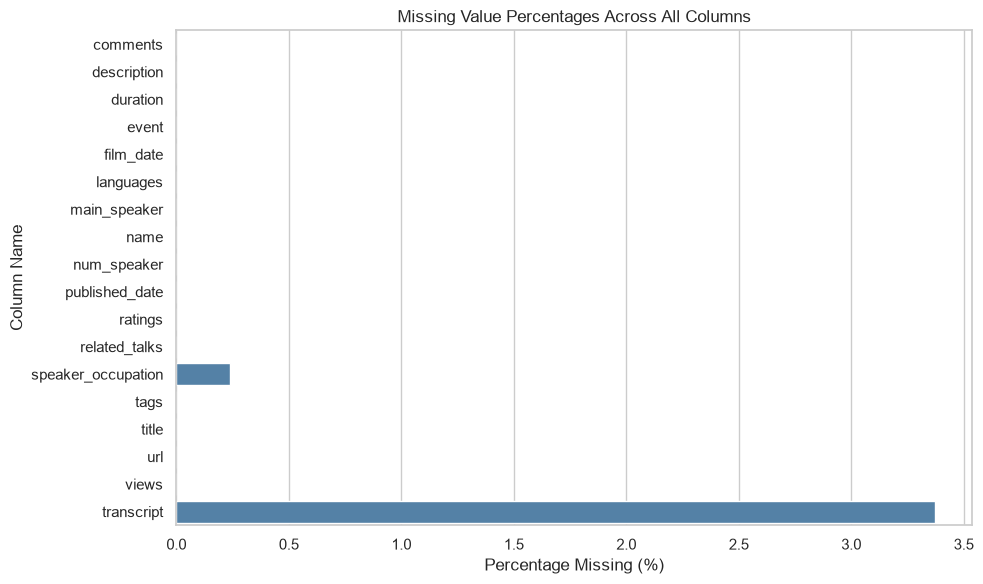

In [13]:


# Calculate missing percentages for all columns in the dataset
missing_percent = (df.isna().mean() * 100).round(2).reset_index()
missing_percent.columns = ['Column', 'Missing Percentage']

# Create a simple, clean visualization for all columns
plt.figure(figsize=(10, 6))
sns.barplot(data=missing_percent, x='Missing Percentage', y='Column', color='steelblue')
plt.title("Missing Value Percentages Across All Columns")
plt.xlabel("Percentage Missing (%)")
plt.ylabel("Column Name")
plt.tight_layout()
plt.show()

Visualizing numeric columns: ['comments', 'duration', 'languages', 'views']


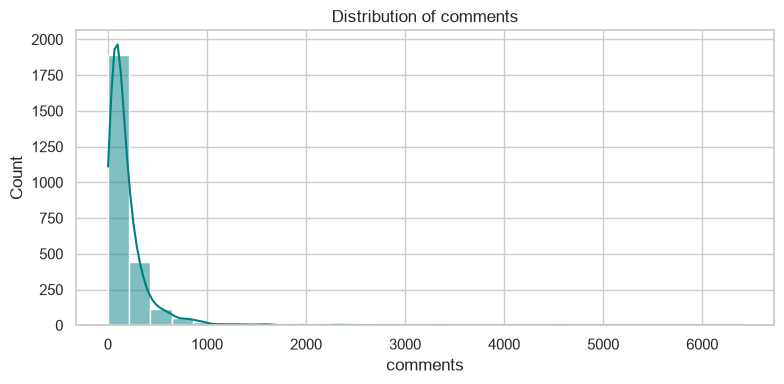

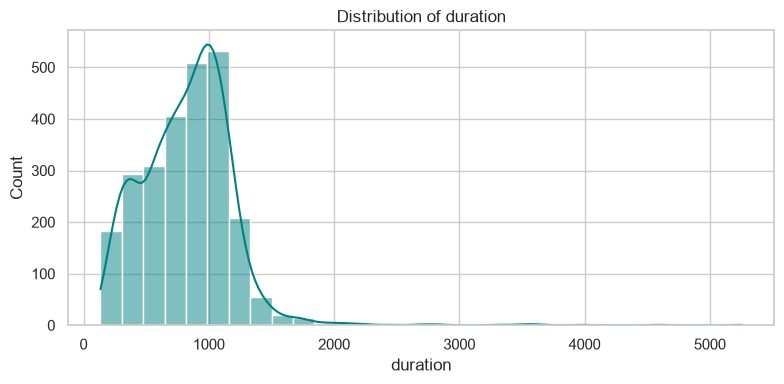

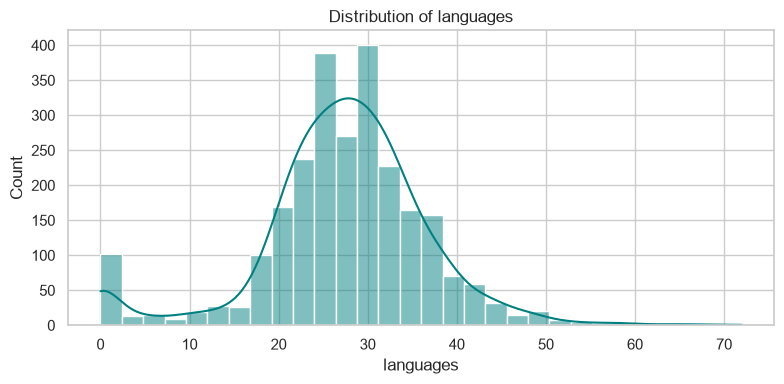

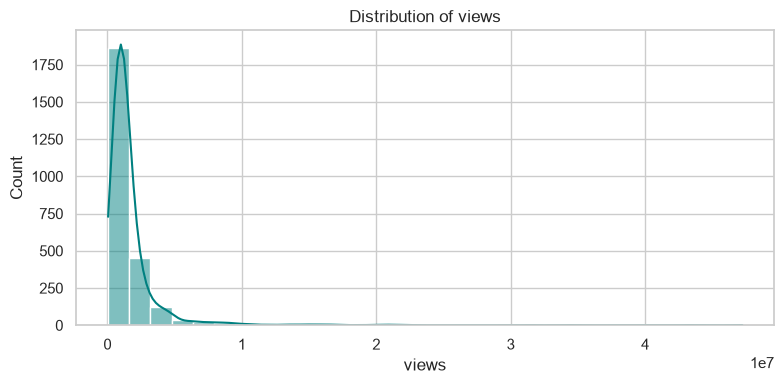


Visualizing categorical columns (Top 10 categories): ['event', 'main_speaker', 'speaker_occupation']


C:\Users\ajayr\AppData\Local\Temp\ipykernel_12040\3525767540.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')


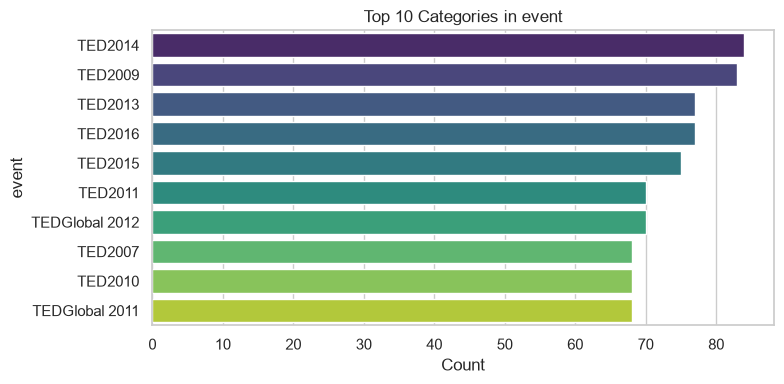

C:\Users\ajayr\AppData\Local\Temp\ipykernel_12040\3525767540.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')


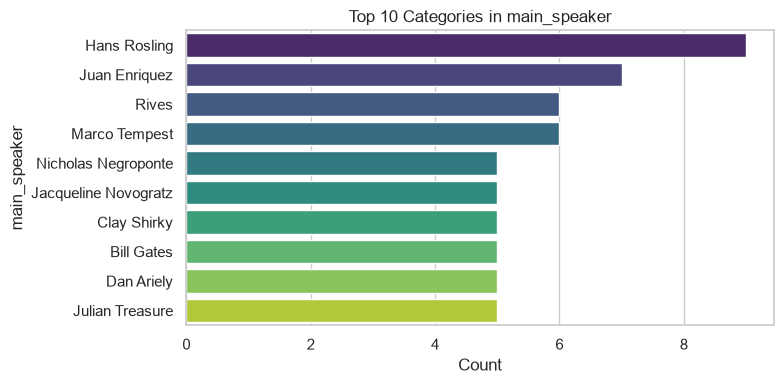

C:\Users\ajayr\AppData\Local\Temp\ipykernel_12040\3525767540.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')


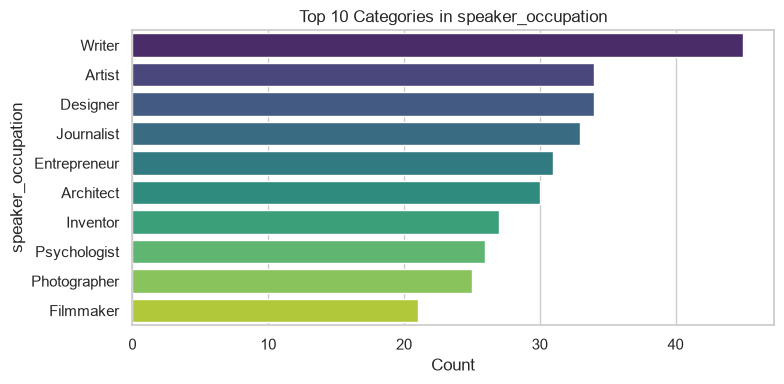

In [14]:


# 1. Identify and visualize numeric distributions
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ['film_date', 'published_date', 'num_speaker']]

print(f"Visualizing numeric columns: {numeric_cols}")
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col].dropna(), bins=30, kde=True, color='teal')
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

# 2. Identify and visualize top categories for categorical columns
cat_cols = ['event', 'main_speaker', 'speaker_occupation']
print(f"\nVisualizing categorical columns (Top 10 categories): {cat_cols}")
for col in cat_cols:
    if col in df.columns:
        plt.figure(figsize=(8, 4))
        top_categories = df[col].value_counts().head(10)
        sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')
        plt.title(f"Top 10 Categories in {col}")
        plt.xlabel("Count")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

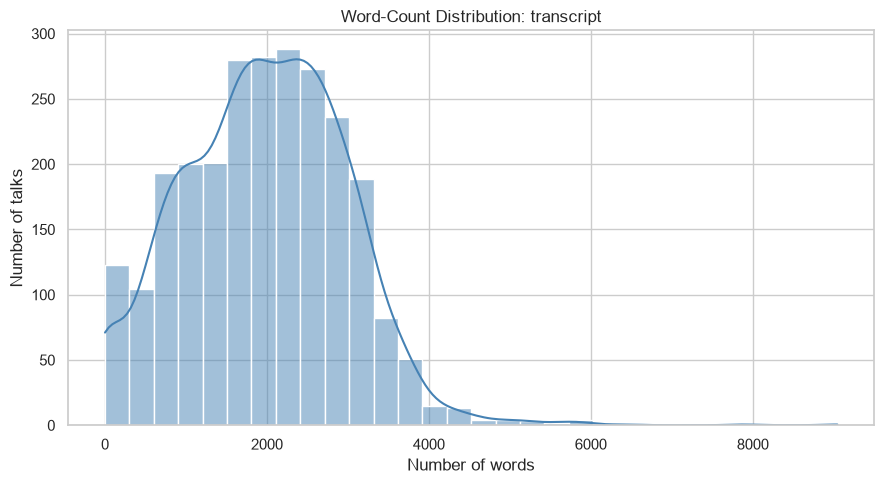

In [15]:
# Chart 2: Transcript word-count distribution (or description if transcript is absent)

# Ensure key variables are defined
transcript_col = 'transcript' if 'transcript' in df.columns else None
description_col = 'description' if 'description' in df.columns else None
# REPORTS_FOLDER = Path("TED-TALK-RECOMMENDATION-SYSTEM/reports")
# REPORTS_FOLDER.mkdir(parents=True, exist_ok=True)

text_column_for_chart = transcript_col if transcript_col is not None else description_col

if text_column_for_chart is not None:
    word_counts = df[text_column_for_chart].fillna("").astype(str).str.split().str.len()
    plt.figure(figsize=(9, 5))
    sns.histplot(word_counts, bins=30, kde=True, color="steelblue")
    plt.title(f"Word-Count Distribution: {text_column_for_chart}")
    plt.xlabel("Number of words")
    plt.ylabel("Number of talks")
    plt.tight_layout()
    # plt.savefig(REPORTS_FOLDER / "02_text_length_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No transcript or description column was found, so the text-length chart was skipped.")

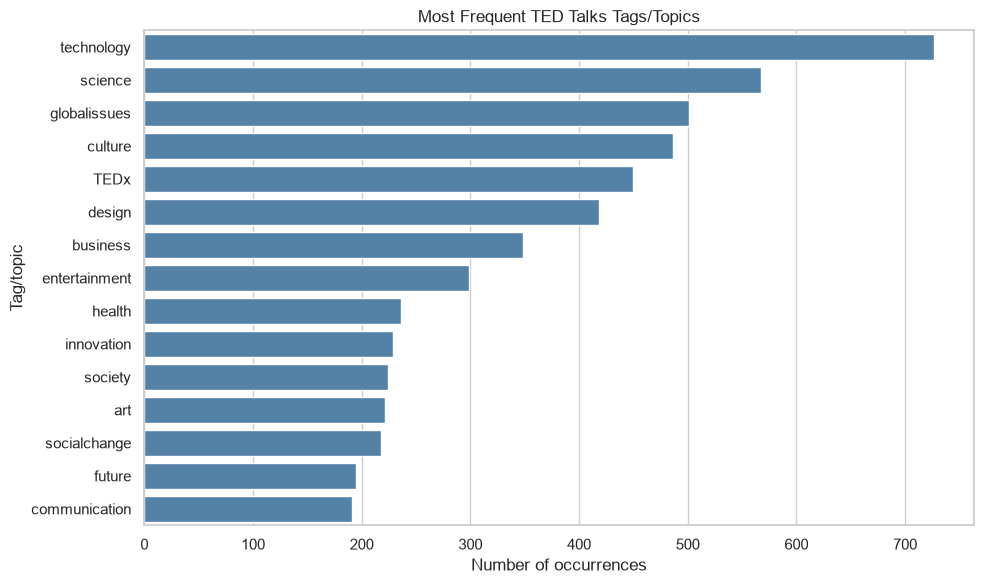

In [16]:
# Chart 3: Top tags/topics


# Ensure REPORTS_FOLDER and tag_counts are defined safely
# REPORTS_FOLDER = Path("TED-TALK-RECOMMENDATION-SYSTEM/reports")
# REPORTS_FOLDER.mkdir(parents=True, exist_ok=True)

if 'tag_counts' not in globals() or tag_counts is None:
    if 'df' in globals() and 'tags' in df.columns:
        tags_series = df['tags'].dropna().astype(str).str.replace(r"[\['\]\" ]", "", regex=True)
        tag_counts = tags_series.str.split(",").explode().value_counts().head(15)
    else:
        tag_counts = []

if len(tag_counts) > 0:
    plt.figure(figsize=(10, 6))
    sns.barplot(x=tag_counts.values, y=tag_counts.index, color="steelblue")
    plt.title("Most Frequent TED Talks Tags/Topics")
    plt.xlabel("Number of occurrences")
    plt.ylabel("Tag/topic")
    plt.tight_layout()
    # plt.savefig(REPORTS_FOLDER / "03_top_tags.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Tag chart skipped because a usable tags/topic column was not found.")

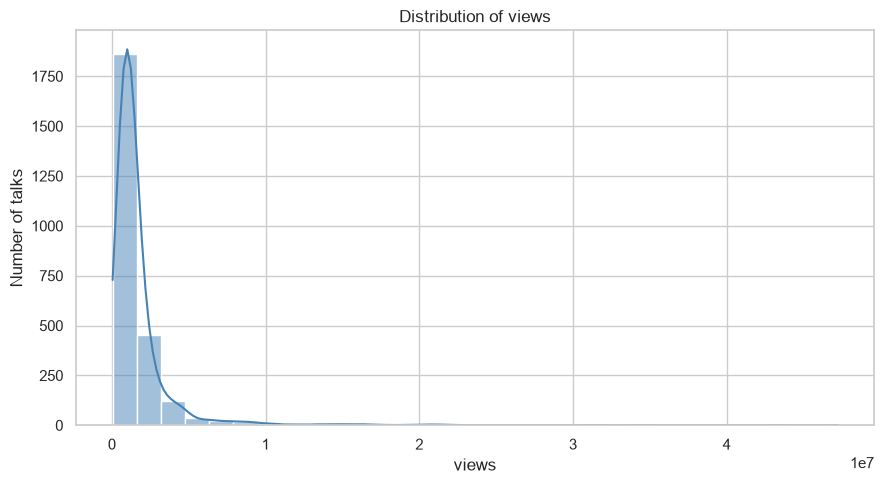

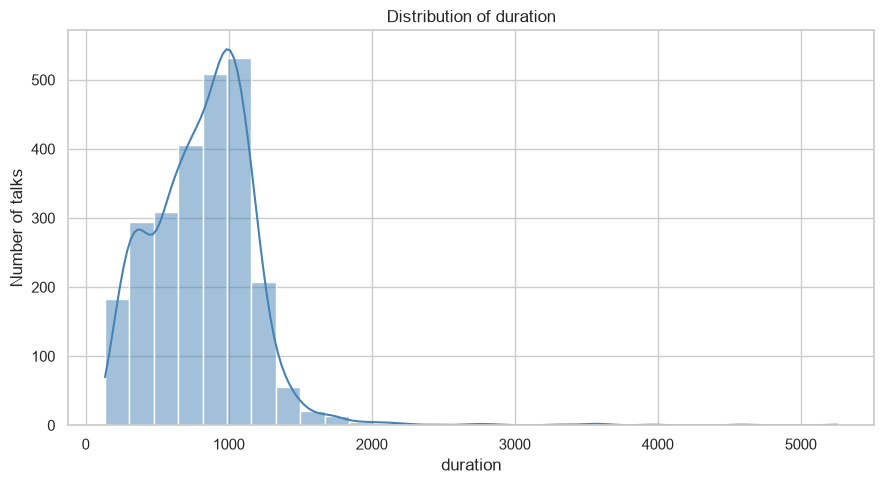

In [17]:
# Chart 4: Distributions for numeric fields such as views or duration
numeric_chart_columns = []
for column in ['views', 'duration']:
    if column is not None and pd.api.types.is_numeric_dtype(df[column]):
        numeric_chart_columns.append(column)

for column in numeric_chart_columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(df[column].dropna(), bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of talks")
    plt.tight_layout()
    plt.show()

if not numeric_chart_columns:
    print("No numeric views/duration column was found. Numeric distribution charts were skipped.")

## 8. Detect numeric outliers

This notebook uses the **IQR method**. It marks values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR` as possible outliers. An outlier is not always an error; unusually high views may be real.

The report below shows the number of possible outliers in each numeric column. ID columns are skipped so identifiers are not treated as measurements.

In [18]:
outlier_results = []
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    if "id" in str(column).lower():
        continue

    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_mask = (df[column] < lower_limit) | (df[column] > upper_limit)

    outlier_results.append({
        "column": column,
        "outlier_count": int(outlier_mask.sum()),
        "lower_limit": lower_limit,
        "upper_limit": upper_limit
    })

outlier_report = pd.DataFrame(outlier_results)
if len(outlier_report) > 0:
    display(outlier_report)
    # outlier_report.to_csv(REPORTS_FOLDER / "outlier_report.csv", index=False)
else:
    print("No suitable numeric measurement columns were found for outlier analysis.")

,column,outlier_count,lower_limit,upper_limit
0,comments,200,-1.751250e+02,4.598750e+02
1,duration,28,-1.276250e+02,1.751375e+03
2,film_date,44,1.024218e+09,1.646212e+09
3,languages,164,8.000000e+00,4.800000e+01
4,num_speaker,58,1.000000e+00,1.000000e+00
5,published_date,0,1.036009e+09,1.655886e+09
6,views,246,-6.616574e+05,3.118210e+06


In [19]:
# Replacing outlier values in-place using statistical methods (IQR capping/clipping)

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    if "id" in str(column).lower():
        continue

    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    # Clip values in-place to the lower and upper limit boundaries
    df[column] = df[column].clip(lower=lower_limit, upper=upper_limit)

print("Outliers replaced successfully in-place.")

Outliers replaced successfully in-place.


## 9. Write at least five findings from the data

These findings are generated from the dataset you loaded. Read them and add your own explanation in the final report if needed.

In [20]:
print("FINDINGS")

print("1. Dataset size:", df.shape[0], "rows and", df.shape[1], "columns.")
print("2. Exact duplicate rows:", int(df.duplicated().sum()))
text_columns = df.select_dtypes(include=['object']).columns.tolist()

if len(missing_report) > 0:
    print(f"3. Column with the highest missing percentage: {missing_report.index[0]} ({missing_report.iloc[0]}%).")
else:
    print("3. No columns were available for missing-value analysis.")


if text_columns:
    print("4. Text fields available for analysis:", ", ".join(map(str, text_columns)))
else:
    print("4. No common text fields were detected.")

if len(tag_counts) > 0:
    print(f"5. Most frequent tag/topic: '{tag_counts.index[0]}' ({int(tag_counts.iloc[0])} occurrences).")
else:
    print("5. Tag frequency could not be calculated because no tags/topic field was detected.")

if len(outlier_report) > 0:
    total_outliers = int(outlier_report["outlier_count"].sum())
    print("6. Possible outliers found across numeric measurement columns:", total_outliers)
else:
    print("6. No numeric measurement columns were available for outlier analysis.")

FINDINGS
1. Dataset size: 2550 rows and 18 columns.
2. Exact duplicate rows: 0
3. Column with the highest missing percentage: Missing Count (comments               0.0
description            0.0
duration               0.0
event                  0.0
film_date              0.0
languages              0.0
main_speaker           0.0
name                   0.0
num_speaker            0.0
published_date         0.0
ratings                0.0
related_talks          0.0
speaker_occupation     6.0
tags                   0.0
title                  0.0
url                    0.0
views                  0.0
transcript            86.0
Name: Missing Count, dtype: float64%).
4. Text fields available for analysis: description, event, main_speaker, name, ratings, related_talks, speaker_occupation, tags, title, url, transcript
5. Most frequent tag/topic: 'technology' (727 occurrences).
6. Possible outliers found across numeric measurement columns: 740


C:\Users\ajayr\AppData\Local\Temp\ipykernel_12040\2401978693.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include=['object']).columns.tolist()


In [27]:
# Drop rows with null values specifically in the target columns before text cleaning replacements occur
rows_before = len(df)
# Identify rows where 'transcript' or 'speaker_occupation' are NaN in the parent dataframe 'df'
clean_df = df.dropna(subset=['transcript', 'speaker_occupation']).copy()
rows_after = len(clean_df)
print(f"Dropped {rows_before - rows_after} rows containing null values in 'transcript' or 'speaker_occupation'.")
print(f"Remaining rows: {rows_after}")

Dropped 92 rows containing null values in 'transcript' or 'speaker_occupation'.
Remaining rows: 2458


## 10. Clean exact duplicate rows and text fields

The original dataset in `data/raw/` is never overwritten. This step works on a copy.

- Exact duplicate rows are removed.
- Missing transcripts are kept; other fields may still be useful for recommendations.
- Text fields get new columns ending in `_clean`, so original text remains available for comparison.
- Repeated IDs or URLs were reported above. Exact rows are removed automatically; conflicting records sharing an ID/URL are left for review rather than risking accidental data loss.

In [29]:
# Clean the remaining exact duplicate rows and standardized text fields in-place on our subset
exact_duplicates_before = int(clean_df.duplicated().sum())
clean_df = clean_df.drop_duplicates().copy()

print("Rows before exact deduplication:", len(clean_df))
print("Exact duplicate rows found:", exact_duplicates_before)

# Clean available text fields in-place, overwriting original columns safely
text_columns_to_clean = [column for column in ["title", "tags", "description", "transcript"] if column in clean_df.columns]

for column in text_columns_to_clean:
    clean_df[column] = clean_df[column].fillna("").astype(str).str.lower().str.strip()
    clean_df[column] = clean_df[column].str.replace(r"\s+", " ", regex=True)

print("Text fields cleaned in-place:", text_columns_to_clean)
print(f"Final row count after deduplication and text cleaning: {len(clean_df)}")

Rows before exact deduplication: 2550
Exact duplicate rows found: 0
Text fields cleaned in-place: ['title', 'tags', 'description', 'transcript']
Final row count after deduplication and text cleaning: 2550


# now lets save the file as eda part is done

In [30]:
# Save the cleaned dataframe after EDA and processing (overwriting with in-place cleaned columns)
import os

output_dir = "/Users/ajayr/Desktop/TED-TALK-RECOMMENDATION-SYSTEM/data/processed"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "ted_talks_cleaned.csv")

clean_df.to_csv(output_path, index=False)
print(f"Updated cleaned dataset saved successfully to: {output_path}")

Updated cleaned dataset saved successfully to: /Users/ajayr/Desktop/TED-TALK-RECOMMENDATION-SYSTEM/data/processed\ted_talks_cleaned.csv


In [31]:
df1=pd.read_csv("/Users/ajayr/Desktop/TED-TALK-RECOMMENDATION-SYSTEM/data/processed/ted_talks_cleaned.csv")
df1.head()

,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views,transcript
0,459.875,sir ken robinson makes an entertaining and pro...,1164.0,TED2006,1140825600,48,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,3118209.625,good morning. how are you?(laughter)it's been ...
1,265.000,with the same humor and humanity he exuded in ...,977.0,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3118209.625,"thank you so much, chris. and it's truly a gre..."
2,124.000,new york times columnist david pogue takes aim...,1286.0,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292.000,"(music: ""the sound of silence,"" simon & garfun..."
3,200.000,"in an emotionally charged talk, macarthur-winn...",1116.0,TED2006,1140912000,35,Majora Carter,Majora Carter: Greening the ghetto,1,1151367060,"[{'id': 3, 'name': 'Courageous', 'count': 760}...","[{'id': 1041, 'hero': 'https://pe.tedcdn.com/i...",Activist for environmental justice,"['macarthur grant', 'activism', 'business', 'c...",greening the ghetto,https://www.ted.com/talks/majora_carter_s_tale...,1697550.000,if you're here today — and i'm very happy that...
4,459.875,you've never seen data presented like this. wi...,1190.0,TED2006,1140566400,48,Hans Rosling,Hans Rosling: The best stats you've ever seen,1,1151440680,"[{'id': 9, 'name': 'Ingenious', 'count': 3202}...","[{'id': 2056, 'hero': 'https://pe.tedcdn.com/i...",Global health expert; data visionary,"['africa', 'asia', 'google', 'demo', 'economic...",the best stats you've ever seen,https://www.ted.com/talks/hans_rosling_shows_t...,3118209.625,"about 10 years ago, i took on the task to teac..."


In [32]:
df1.columns

Index(['comments', 'description', 'duration', 'event', 'film_date',
       'languages', 'main_speaker', 'name', 'num_speaker', 'published_date',
       'ratings', 'related_talks', 'speaker_occupation', 'tags', 'title',
       'url', 'views', 'transcript'],
      dtype='str')

In [33]:
df.columns

Index(['comments', 'description', 'duration', 'event', 'film_date',
       'languages', 'main_speaker', 'name', 'num_speaker', 'published_date',
       'ratings', 'related_talks', 'speaker_occupation', 'tags', 'title',
       'url', 'views', 'transcript'],
      dtype='str')

In [34]:
df1.isna().sum()

comments               0
description            0
duration               0
event                  0
film_date              0
languages              0
main_speaker           0
name                   0
num_speaker            0
published_date         0
ratings                0
related_talks          0
speaker_occupation     6
tags                   0
title                  0
url                    0
views                  0
transcript            86
dtype: int64